# Canal 2, gene axis: is the training-free NEIGHBORHOOD signal also concentrated on the genes the model predicts worst?

The same reading as `classic.ipynb` and its epistemic twin, applied to the kNN signals. The head's own spread is not drawn here: it is the subject of the first of those notebooks.

Grouping is `(gene, slide)`, so the error is ranked **across the spots of one gene**. Slides are folded to one controlled correlation per gene, genes are split into deciles of their prediction accuracy, and the median absolute correlation of each decile is drawn over a cloud of one point per gene. Worst-predicted genes on the left, so a **decline left to right** means the correlation lives on the genes the model predicts worst.

### Why the distance signals are measurable here

`d_mean` and the normalized distances take **one value per spot**. They are therefore constant inside a group of the SPOT axis and silent there, exactly as a gene-homoscedastic variance is silent on the gene axis. On the GENE axis a group is one gene across many spots, so a per-spot signal does vary and is measurable. That is why this notebook exists on this axis and would be empty on the other.

### Two limits carried into the caption

`sigma_knn` is undefined where a spot has fewer than five detected neighbors, so it is not scored on exactly the same entries as the distance signals. And the signals are a property of the cohort, not of the model: the head enters only through the ERROR, which is why one row per head still shows different curves.

Everything here comes from `pr_classic3`, signals and accuracy alike, so unlike the epistemic version there is no mixing of training arms.

Run on cluster Jupyter.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))

# =============================== SETTINGS ====================================
RUN_ID   = "pr_classic3"
RESULTS  = PROJ / "results"
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"
LAMBDA   = "lambda_0.0"    # leaf of the Gaussian heads in the single-model tree
CASE     = "lin_pos"

# One ROW per head. The head enters only through the ERROR : the kNN signal does not depend on
# the model. The heads mute on the gene axis (gene-homoscedastic Gaussian, Poisson) have no
# place here.
HEADS    = ["heteroscedastic", "negativebinomial_hetero_noanchor_cp"]
GAUSSIAN = {"heteroscedastic", "homoscedastic", "spot_homoscedastic"}

# The three signals that cover the three cohorts. The two normalizations by tissue radius
# exist on one cohort each (10x_TuPro fully annotated, TLS via the imputed annotation,
# LUNG_CANCER not annotated), so they cannot appear in a shared figure
# between cohorts.
SIGNALS = [
    dict(key="sigma",   name="kNN local dispersion",         subdir="canal2_knn_sigma_knn"),
    dict(key="dmean",   name="kNN distance (raw)",           subdir="canal2_knn_d_mean"),
    dict(key="dleiden", name="kNN distance / leiden radius", subdir="canal2_knn_d_norm_leiden"),
]

RANK_METRIC = "pearson"
NBINS       = 10
FIGDIR      = PROJ / "results" / "_analysis" / "figures"
# =============================================================================

N_PLUS_MIN, CONVENTION = 60, "v3_native_scale"
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
MIN_SLIDES = 3

# One color per SIGNAL, never per model : here the models are the ROWS, named on the y
# axis, and the color encodes only the signal. Do not carry this palette into a figure
# where a model would be encoded by a color.
SIGNAL_COLORS = {"sigma": "m", "dmean": "c", "dleiden": "k"}
MODEL_LABELS = {
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}


def leaf_of(model):
    return f"{model}/{LAMBDA}" if model in GAUSSIAN else model


def canal2_dir(sig, ds, model):
    """The kNN mode writes under the MODEL folder, not under the kNN folder : a single kNN
    folder serves the whole cohort, so writing there would make the models collide."""
    return RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS / leaf_of(model) / sig["subdir"]


PAIR, missing, stale, na = {}, [], [], []
for sig in SIGNALS:
    for ds in DATASETS:
        for m in HEADS:
            d = canal2_dir(sig, ds, m)
            if not (d / "summary.json").is_file():
                missing.append((sig["key"], ds, m))
                continue
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable"):
                na.append((sig["key"], ds, m))
                continue
            if s.get("canal2_convention") != CONVENTION:
                stale.append((sig["key"], ds, m, s.get("canal2_convention")))
                continue
            f = d / "pair_partial.parquet"
            if f.is_file():
                PAIR[(sig["key"], ds, m)] = pd.read_parquet(f)

print(f"run {RUN_ID}   case = {CASE!r}")
print(f"INVENTORY, out of a maximum of {len(DATASETS) * len(HEADS)} per signal")
for sig in SIGNALS:
    got = sum(1 for (k, _, _) in PAIR if k == sig["key"])
    print(f"  {sig['name']:<34s} {sig['subdir']:<34s} {got:>2d} run(s)")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r}, DROPPED: "
          f"{stale[:6]}")
if na:
    print(f"\n{len(na)} run(s) 'not_applicable' : {na[:6]}")
if missing:
    print(f"\n(!) {len(missing)} (signal, cohort, head) with no summary.json :")
    for k in sorted({x[0] for x in missing}):
        w = [f"{ds}/{m}" for (kk, ds, m) in missing if kk == k]
        print(f"    {k:<8s} {len(w):>2d} : {w[:4]}{' ...' if len(w) > 4 else ''}")

run pr_classic3   case = 'lin_pos'
INVENTORY, out of a maximum of 6 per signal
  kNN local dispersion               canal2_knn_sigma_knn                6 run(s)
  kNN distance (raw)                 canal2_knn_d_mean                   6 run(s)
  kNN distance / leiden radius       canal2_knn_d_norm_leiden            6 run(s)


In [2]:
# ── THE X AXIS : one accuracy per (cohort, gene), shared by every signal ──────────────────────
# Donor cascade, the one in src/evaluation/benchmark_summary.py : one value per (donor, gene),
# then mean over the donors, then mean over the listed heads. Intersection of the genes
# present in every head, otherwise a gene missing from one head would shift the axis.
ACC = {}
for ds in DATASETS:
    pieces, shared = [], None
    for m in HEADS:
        f = (RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS / leaf_of(m)
             / "benchmark_summary.parquet")
        if not f.is_file():
            print(f"  (!) no benchmark_summary.parquet for {ds} / {m}")
            continue
        b = pd.read_parquet(f)
        if RANK_METRIC not in b.columns or "gene" not in b.columns:
            print(f"  (!) {RANK_METRIC} absent de {f}")
            continue
        per_gene = b.groupby("gene")[RANK_METRIC].mean()      # mean over the donors
        shared = set(per_gene.index) if shared is None else (shared & set(per_gene.index))
        pieces.append(per_gene)
    if not pieces or not shared:
        print(f"  (!) {ds}: accuracy axis impossible to build")
        continue
    shared = sorted(shared)
    ACC[ds] = (pd.concat([p.loc[shared] for p in pieces], axis=1).mean(axis=1)
                 .rename("pred_corr").reset_index())
    print(f"  {DATASET_LABELS[ds]:<22s} axis over {len(ACC[ds]):,} shared genes, "
          f"{len(pieces)} head(s) averaged")


# ── THE VALUE : one controlled correlation per gene, slides folded ────────────────────────────
def gene_level(frame):
    """The slides folded with a weight equal to the group size, the canal 2 cascade."""
    col, ncol = f"r_partial_{CASE}", N_COL[CASE]
    if frame is None or col not in frame.columns:
        return None
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return None
    t = pd.DataFrame({"gene": d["gene"].to_numpy(),
                      "w":    d[ncol].to_numpy(float),
                      "wr":   d[ncol].to_numpy(float) * d[col].to_numpy(float)})
    g = t.groupby("gene", sort=True)
    out = pd.DataFrame({"r": g["wr"].sum() / g["w"].sum(), "n_slides": g.size()}).reset_index()
    return out[out["n_slides"] >= MIN_SLIDES]


GL = {}
for (k, ds, m), frame in PAIR.items():
    gl = gene_level(frame)
    if gl is None or ds not in ACC:
        continue
    d = gl.merge(ACC[ds], on="gene")
    GL[(k, ds, m)] = d[np.isfinite(d["pred_corr"]) & np.isfinite(d["r"])]
print(f"\n{len(GL)} curves (signal, cohort, head) ready")

# The number of genes kept differs between signals : sigma_knn is undefined where a spot has
# fewer than five detected neighbors. Say it from the data rather than in a comment.
print("\ngenes kept per (cohort, head, signal)")
for ds in DATASETS:
    for m in HEADS:
        got = {k[0]: len(GL[k]) for k in GL if k[1] == ds and k[2] == m}
        if got:
            print(f"  {DATASET_LABELS[ds]:<22s} {MODEL_LABELS.get(m, m):<28s} {got}")

  Tumor Profiler         axis over 3,000 shared genes, 2 head(s) averaged
  Kidney/Lung with TLS   axis over 3,000 shared genes, 2 head(s) averaged
  NSCLC                  axis over 3,000 shared genes, 2 head(s) averaged

18 curves (signal, cohort, head) ready

genes kept per (cohort, head, signal)
  Tumor Profiler         Gaussian heteroscedastic     {'sigma': 2553, 'dmean': 2746, 'dleiden': 2746}
  Tumor Profiler         Negative binomial            {'sigma': 2545, 'dmean': 2740, 'dleiden': 2740}
  Kidney/Lung with TLS   Gaussian heteroscedastic     {'sigma': 1281, 'dmean': 1925, 'dleiden': 1925}
  Kidney/Lung with TLS   Negative binomial            {'sigma': 1239, 'dmean': 1843, 'dleiden': 1843}
  NSCLC                  Gaussian heteroscedastic     {'sigma': 1794, 'dmean': 2682, 'dleiden': 2682}
  NSCLC                  Negative binomial            {'sigma': 1776, 'dmean': 2640, 'dleiden': 2640}


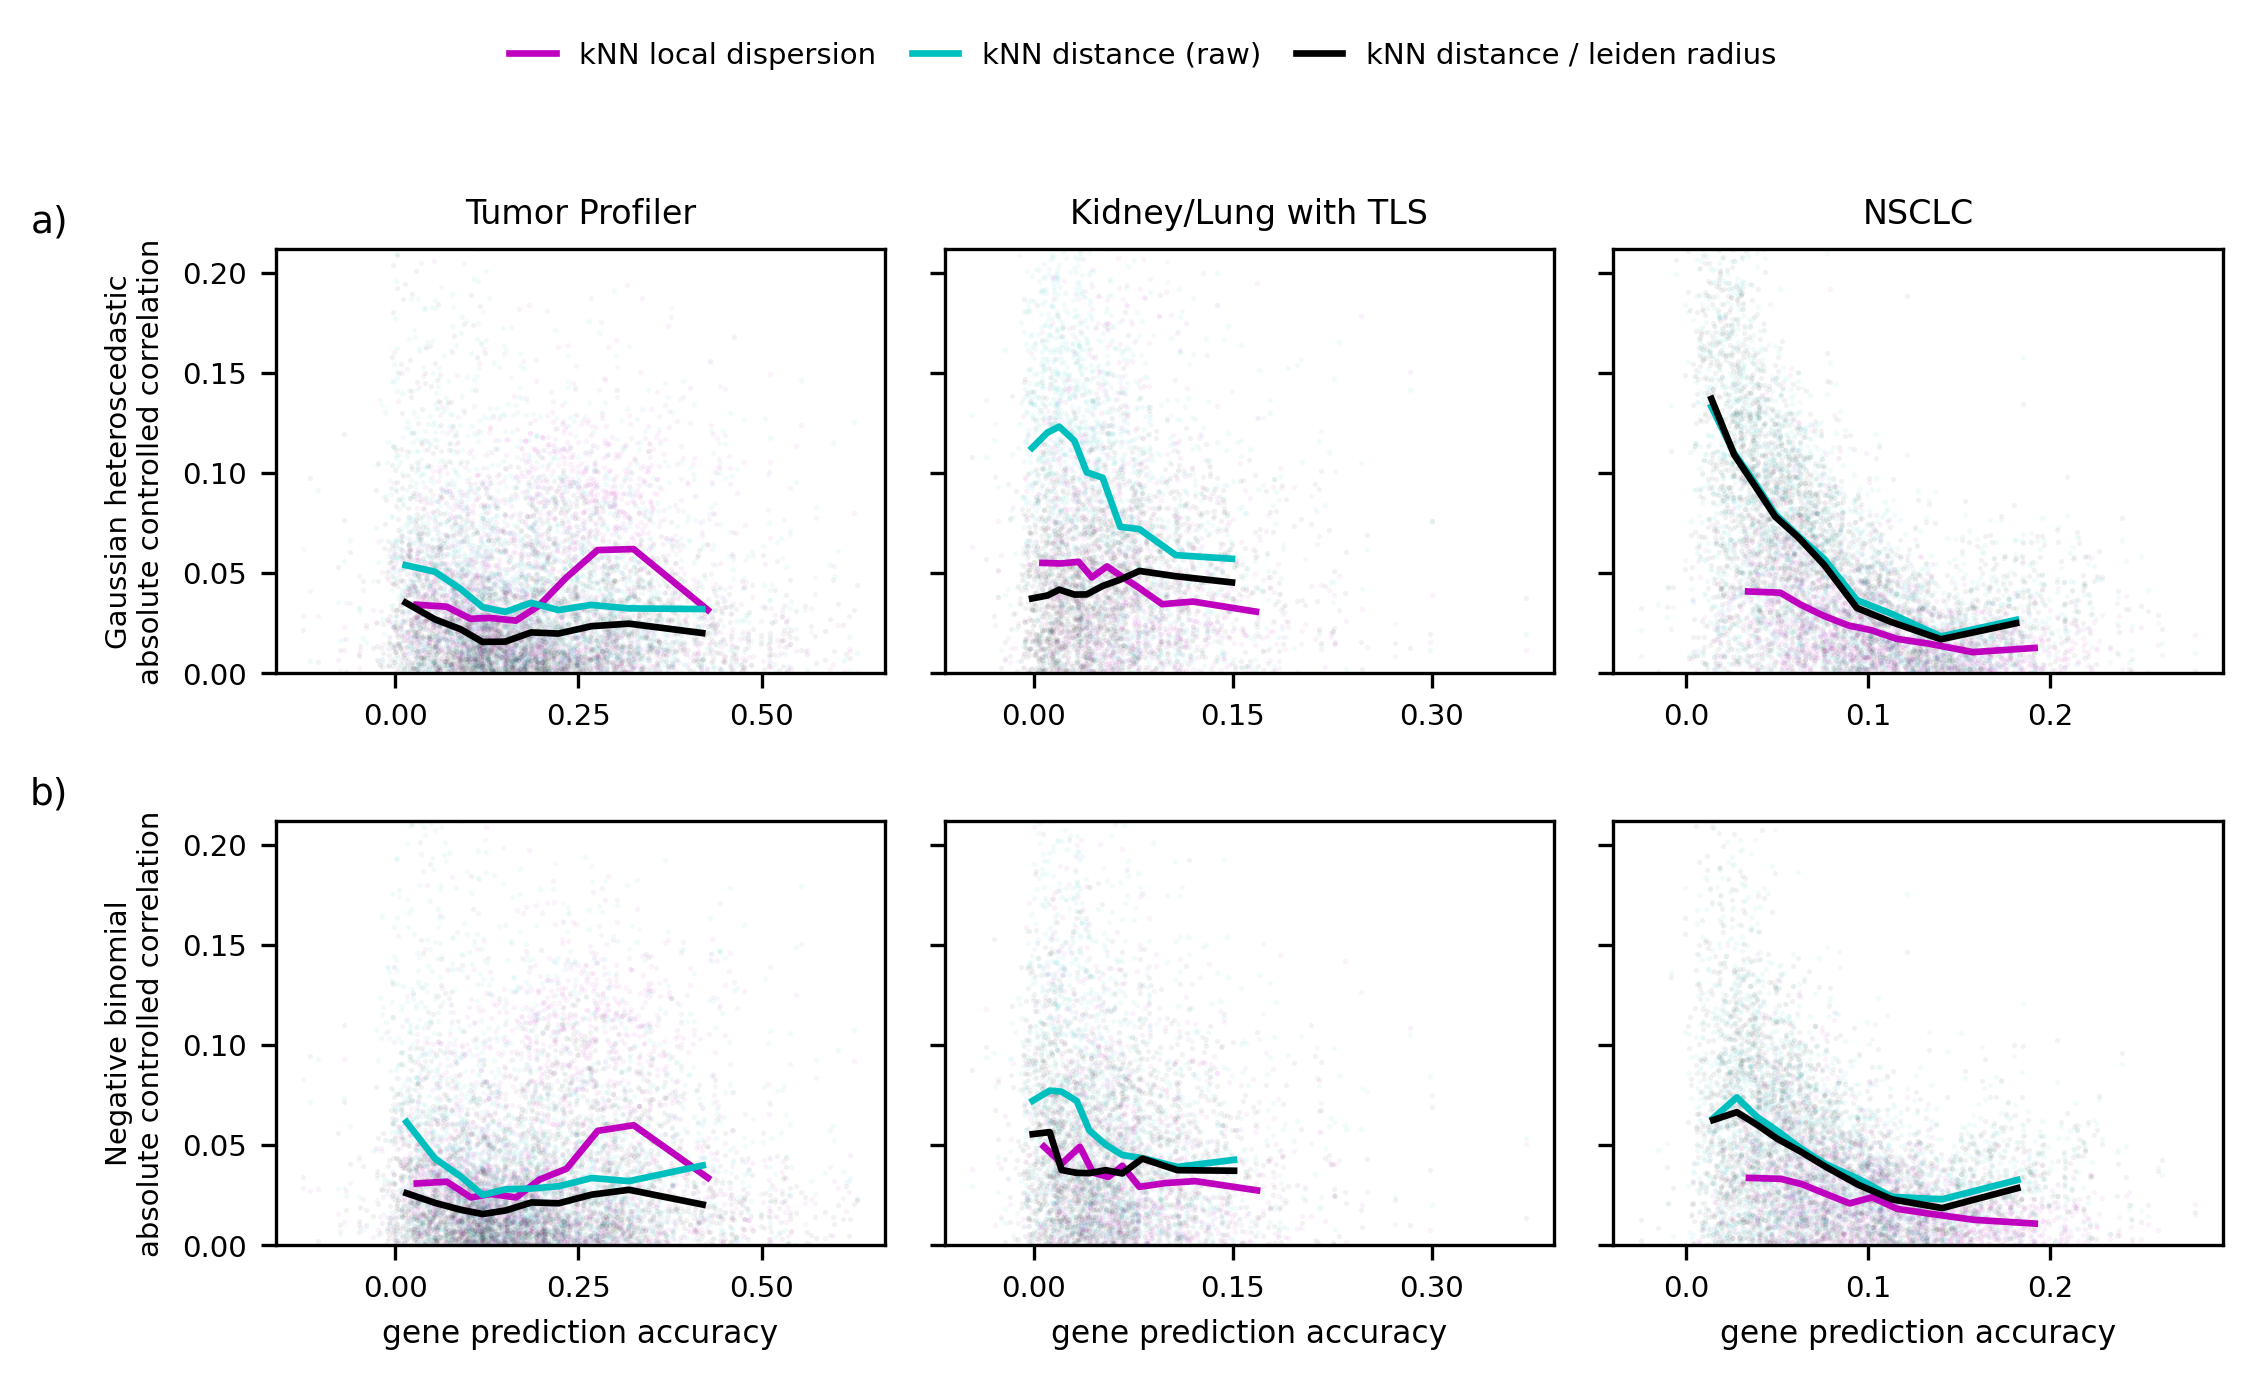

## FIGURE  fig_canal2_gene_axis_predictability_knn_lin_pos_pr_classic3.pdf
## TITLE   The controlled error-uncertainty correlation of the training-free neighborhood signals, against how well the gene is predicted
## CAPTION Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene
## CAPTION and slide, ranking the error across the spots of that gene.
## CAPTION Rows are the predictive heads, columns the three cohorts, colors the neighborhood
## CAPTION signals: the dispersion of the measured expression among a spot's nearest neighbors in
## CAPTION the embedding space, and the distance to those neighbors in two normalizations. The
## CAPTION head's own spread is not drawn here.
## CAPTION The signals are a property of the cohort, not of the model: a head enters only through
## CAPTION the ERROR, which is why the rows differ although the signal does not.
## CAPTION One translucent point per gene and per signal, its prediction accuracy against the
## CAPTION

In [3]:
FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


# The scatter : one point per gene and per signal. rasterized=True keeps the PDF light, the line
# and text stay vector. The view is capped at a percentile, otherwise a few extreme genes stretch
# the axis and squash the medians flat against zero.
SCATTER_S     = 1.6
SCATTER_ALPHA = 0.05
YCLIP_Q       = 99.0

all_abs = (np.concatenate([GL[k]["r"].abs().to_numpy() for k in GL]) if GL
           else np.array([0.0]))
y_hi  = float(np.nanpercentile(all_abs, YCLIP_Q))
above = float((all_abs > y_hi).mean())

fig, axes = plt.subplots(len(HEADS), len(DATASETS),
                         figsize=(2.5 * len(DATASETS), 2.3 * len(HEADS)),
                         dpi=300, sharey="row")
axes = np.atleast_2d(axes)
drawn = []
for i, m in enumerate(HEADS):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for sig in SIGNALS:
            d = GL.get((sig["key"], ds, m))
            if d is None or d.empty:
                continue
            c = SIGNAL_COLORS[sig["key"]]
            ax.scatter(d["pred_corr"], d["r"].abs(), s=SCATTER_S, alpha=SCATTER_ALPHA,
                       color=c, linewidths=0, rasterized=True, zorder=1)
            b = pd.qcut(d["pred_corr"], NBINS, labels=False, duplicates="drop")
            gb = d.assign(abs_r=d["r"].abs()).groupby(b, observed=True)
            x, y, s = (gb["pred_corr"].median().to_numpy(), gb["abs_r"].median().to_numpy(),
                       gb["r"].median().to_numpy())
            ax.plot(x, y, "-", lw=1.6, color=c, zorder=3)
            rho = float(d["r"].abs().corr(d["pred_corr"], method="spearman"))
            for xi, yi, si, ni in zip(x, y, s, gb.size().to_numpy()):
                drawn.append(dict(cohort=ds, head=m, signal=sig["key"], acc_bin_median=xi,
                                  abs_assoc_median=yi, assoc_median=si, n_genes=int(ni),
                                  rho_genes=rho))
        ax.set_ylim(0.0, y_hi)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(DATASET_LABELS[ds], fontsize=8)
        if i == len(HEADS) - 1:
            ax.set_xlabel("gene prediction accuracy", fontsize=7.5)
        if j == 0:
            ax.set_ylabel(f"{MODEL_LABELS.get(m, m)}\nabsolute controlled correlation",
                          fontsize=7)
            ax.text(-0.34, 1.02, f"{'abcd'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)

handles = [Line2D([], [], color=SIGNAL_COLORS[s["key"]], lw=1.6, label=s["name"])
           for s in SIGNALS if any(k[0] == s["key"] for k in GL)]
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3,
           frameon=False, fontsize=7, handlelength=1.6, columnspacing=1.2)

fig_show(fig, FIGDIR / f"fig_canal2_gene_axis_predictability_knn_{CASE}_{RUN_ID}",
         "The controlled error-uncertainty correlation of the training-free neighborhood "
         "signals, against how well the gene is predicted",
         ["Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene",
          "and slide, ranking the error across the spots of that gene.",
          "Rows are the predictive heads, columns the three cohorts, colors the neighborhood",
          "signals: the dispersion of the measured expression among a spot's nearest neighbors in",
          "the embedding space, and the distance to those neighbors in two normalizations. The",
          "head's own spread is not drawn here.",
          "The signals are a property of the cohort, not of the model: a head enters only through",
          "the ERROR, which is why the rows differ although the signal does not.",
          "One translucent point per gene and per signal, its prediction accuracy against the",
          f"absolute value of its controlled correlation; the line is the median over {NBINS} deciles",
          "of that accuracy. Absolute, because genes of opposite sign would otherwise cancel.",
          f"The view is clipped at the {YCLIP_Q:g}th percentile, which leaves {above:.1%} of the genes",
          "above the frame; they are in the median but not drawn.",
          "Worst predicted genes on the left, so a decline left to right means the correlation",
          "lives on the genes the model predicts worst.",
          "The distance signals take one value per spot. They are constant inside a group of the",
          "spot axis and silent there, but they do vary across the spots of one gene, which is the",
          "grouping used here.",
          "The neighborhood dispersion is undefined where a spot has fewer than five detected",
          "neighbors, so it is not scored on exactly the same entries as the distances; the gene",
          "counts of each signal are printed by the preceding cell.",
          "One accuracy per cohort and gene, shared by every signal: per donor and gene, then",
          f"averaged over donors and over heads. Signals and accuracy both come from {RUN_ID}."])

print()
print("=" * 96)
print("THE PRINTED TWIN - the slope, one number per (cohort, head, signal)")
print("=" * 96)
D = pd.DataFrame(drawn)
if not D.empty:
    slope = D.groupby(["cohort", "head", "signal"])["rho_genes"].first().reset_index()
    piv = slope.pivot_table(index=["cohort", "head"], columns="signal", values="rho_genes")
    print(piv.round(3).to_string())
    print()
    print("rho = Spearman over ALL genes between the gene's accuracy and the ABSOLUTE value of its")
    print("      controlled correlation. NEGATIVE = the correlation lives on badly predicted genes.")
    print()
    print("=" * 96)
    print("THE PRINTED TWIN - the plotted points")
    print("=" * 96)
    for ds in DATASETS:
        for m in HEADS:
            sub = D[(D["cohort"] == ds) & (D["head"] == m)]
            if sub.empty:
                continue
            print(f"\n--- {DATASET_LABELS[ds]} / {MODEL_LABELS.get(m, m)} ---")
            print(sub.pivot_table(index="acc_bin_median", columns="signal",
                                  values="abs_assoc_median").round(4).to_string())
else:
    print("(!) nothing plotted -- check the inventory in cell 2")